In [80]:
import os 
import pandas as pd 

cell_type: str = "Fluo-C2DL-Huh7"
ds_type: str = "train"
data_dir: str = os.path.join("..", "..") 
track_filename: str = "man_track.txt"

class Movie:
    one: str = "01"
    two: str = "02"
    
tra_dir: str = os.path.join(data_dir, ds_type, cell_type, f"{Movie.one}_GT", "TRA") 
seg_dir: str = os.path.join(data_dir, ds_type, cell_type, f"{Movie.one}_GT", "SEG")
raw_dir: str = os.path.join(data_dir, ds_type, cell_type, Movie.one)
track_path: str = os.path.join(tra_dir, track_filename)

tracks = pd.read_csv(
    track_path,
    sep=r"\s+",
    header=None,
    names=[
        "cell_id",
        "start_frame",
        "end_frame",
        "parent_id"
    ]
)

tracks


,cell_id,start_frame,end_frame,parent_id
0,1,0,29,0
1,2,0,29,0
2,3,0,29,0
3,4,0,29,0
4,5,0,29,0
5,6,0,29,0
6,7,0,29,0
7,8,0,29,0
8,9,0,29,0
9,10,0,29,0


In [81]:
tracks.loc[tracks["start_frame"] == 0]

,cell_id,start_frame,end_frame,parent_id
0,1,0,29,0
1,2,0,29,0
2,3,0,29,0
3,4,0,29,0
4,5,0,29,0
5,6,0,29,0
6,7,0,29,0
7,8,0,29,0
8,9,0,29,0
9,10,0,29,0


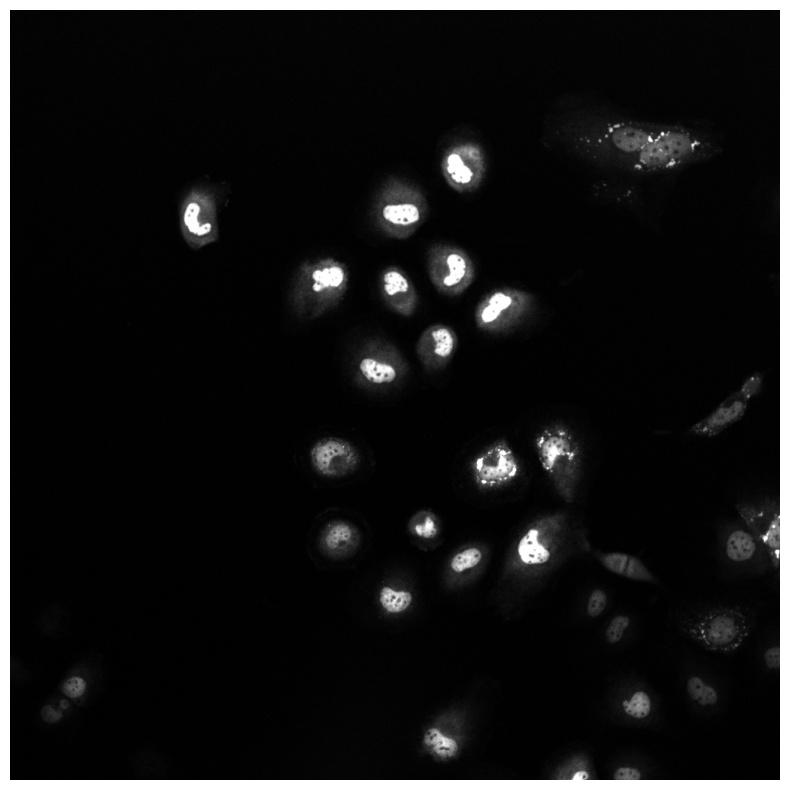

In [86]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_path = os.path.join(raw_dir, "t000.tif")

image = Image.open(image_path)

plt.figure(figsize=(10, 10))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

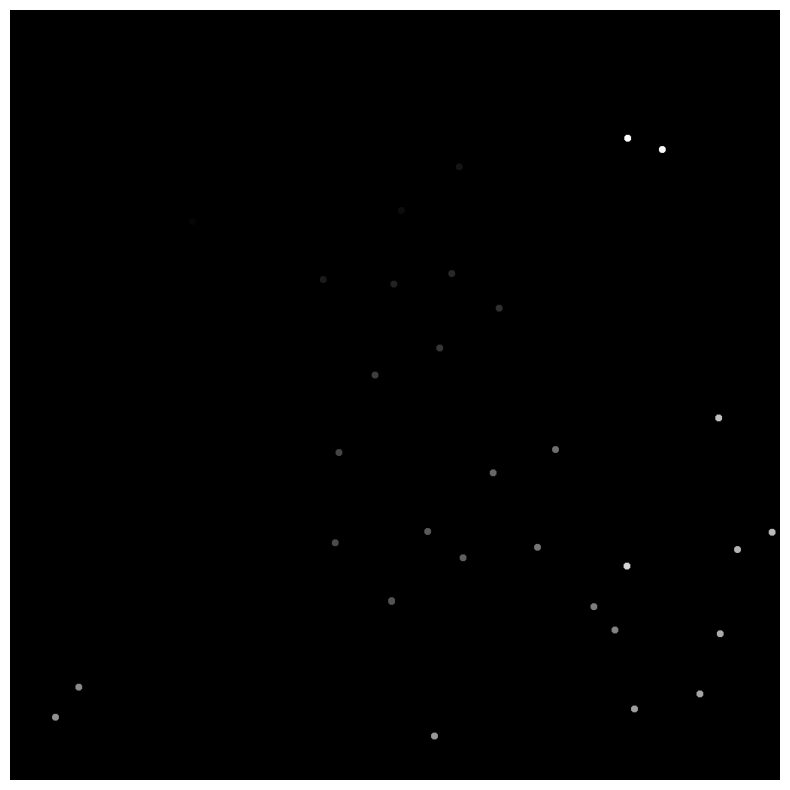

In [87]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_path = os.path.join(tra_dir, "man_track000.tif")

image = Image.open(image_path)

plt.figure(figsize=(10, 10))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

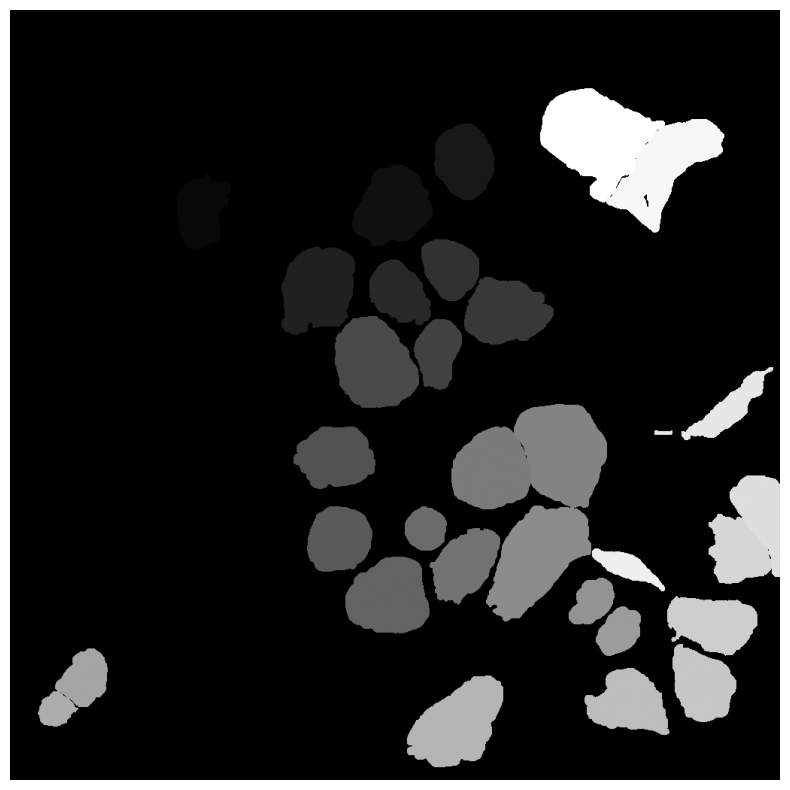

In [88]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_path = os.path.join(seg_dir, "man_seg000.tif")

image = Image.open(image_path)

plt.figure(figsize=(10, 10))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [89]:
tracks.sort_values(by="start_frame", ascending=True)

,cell_id,start_frame,end_frame,parent_id
0,1,0,29,0
1,2,0,29,0
2,3,0,29,0
3,4,0,29,0
4,5,0,29,0
5,6,0,29,0
6,7,0,29,0
7,8,0,29,0
8,9,0,29,0
9,10,0,29,0


In [90]:
tracks_sorted

,cell_id,start_frame,end_frame,parent_id
0,1,0,911,0


Cell: 31
Life: 0 → 3
Children: [32, 34]


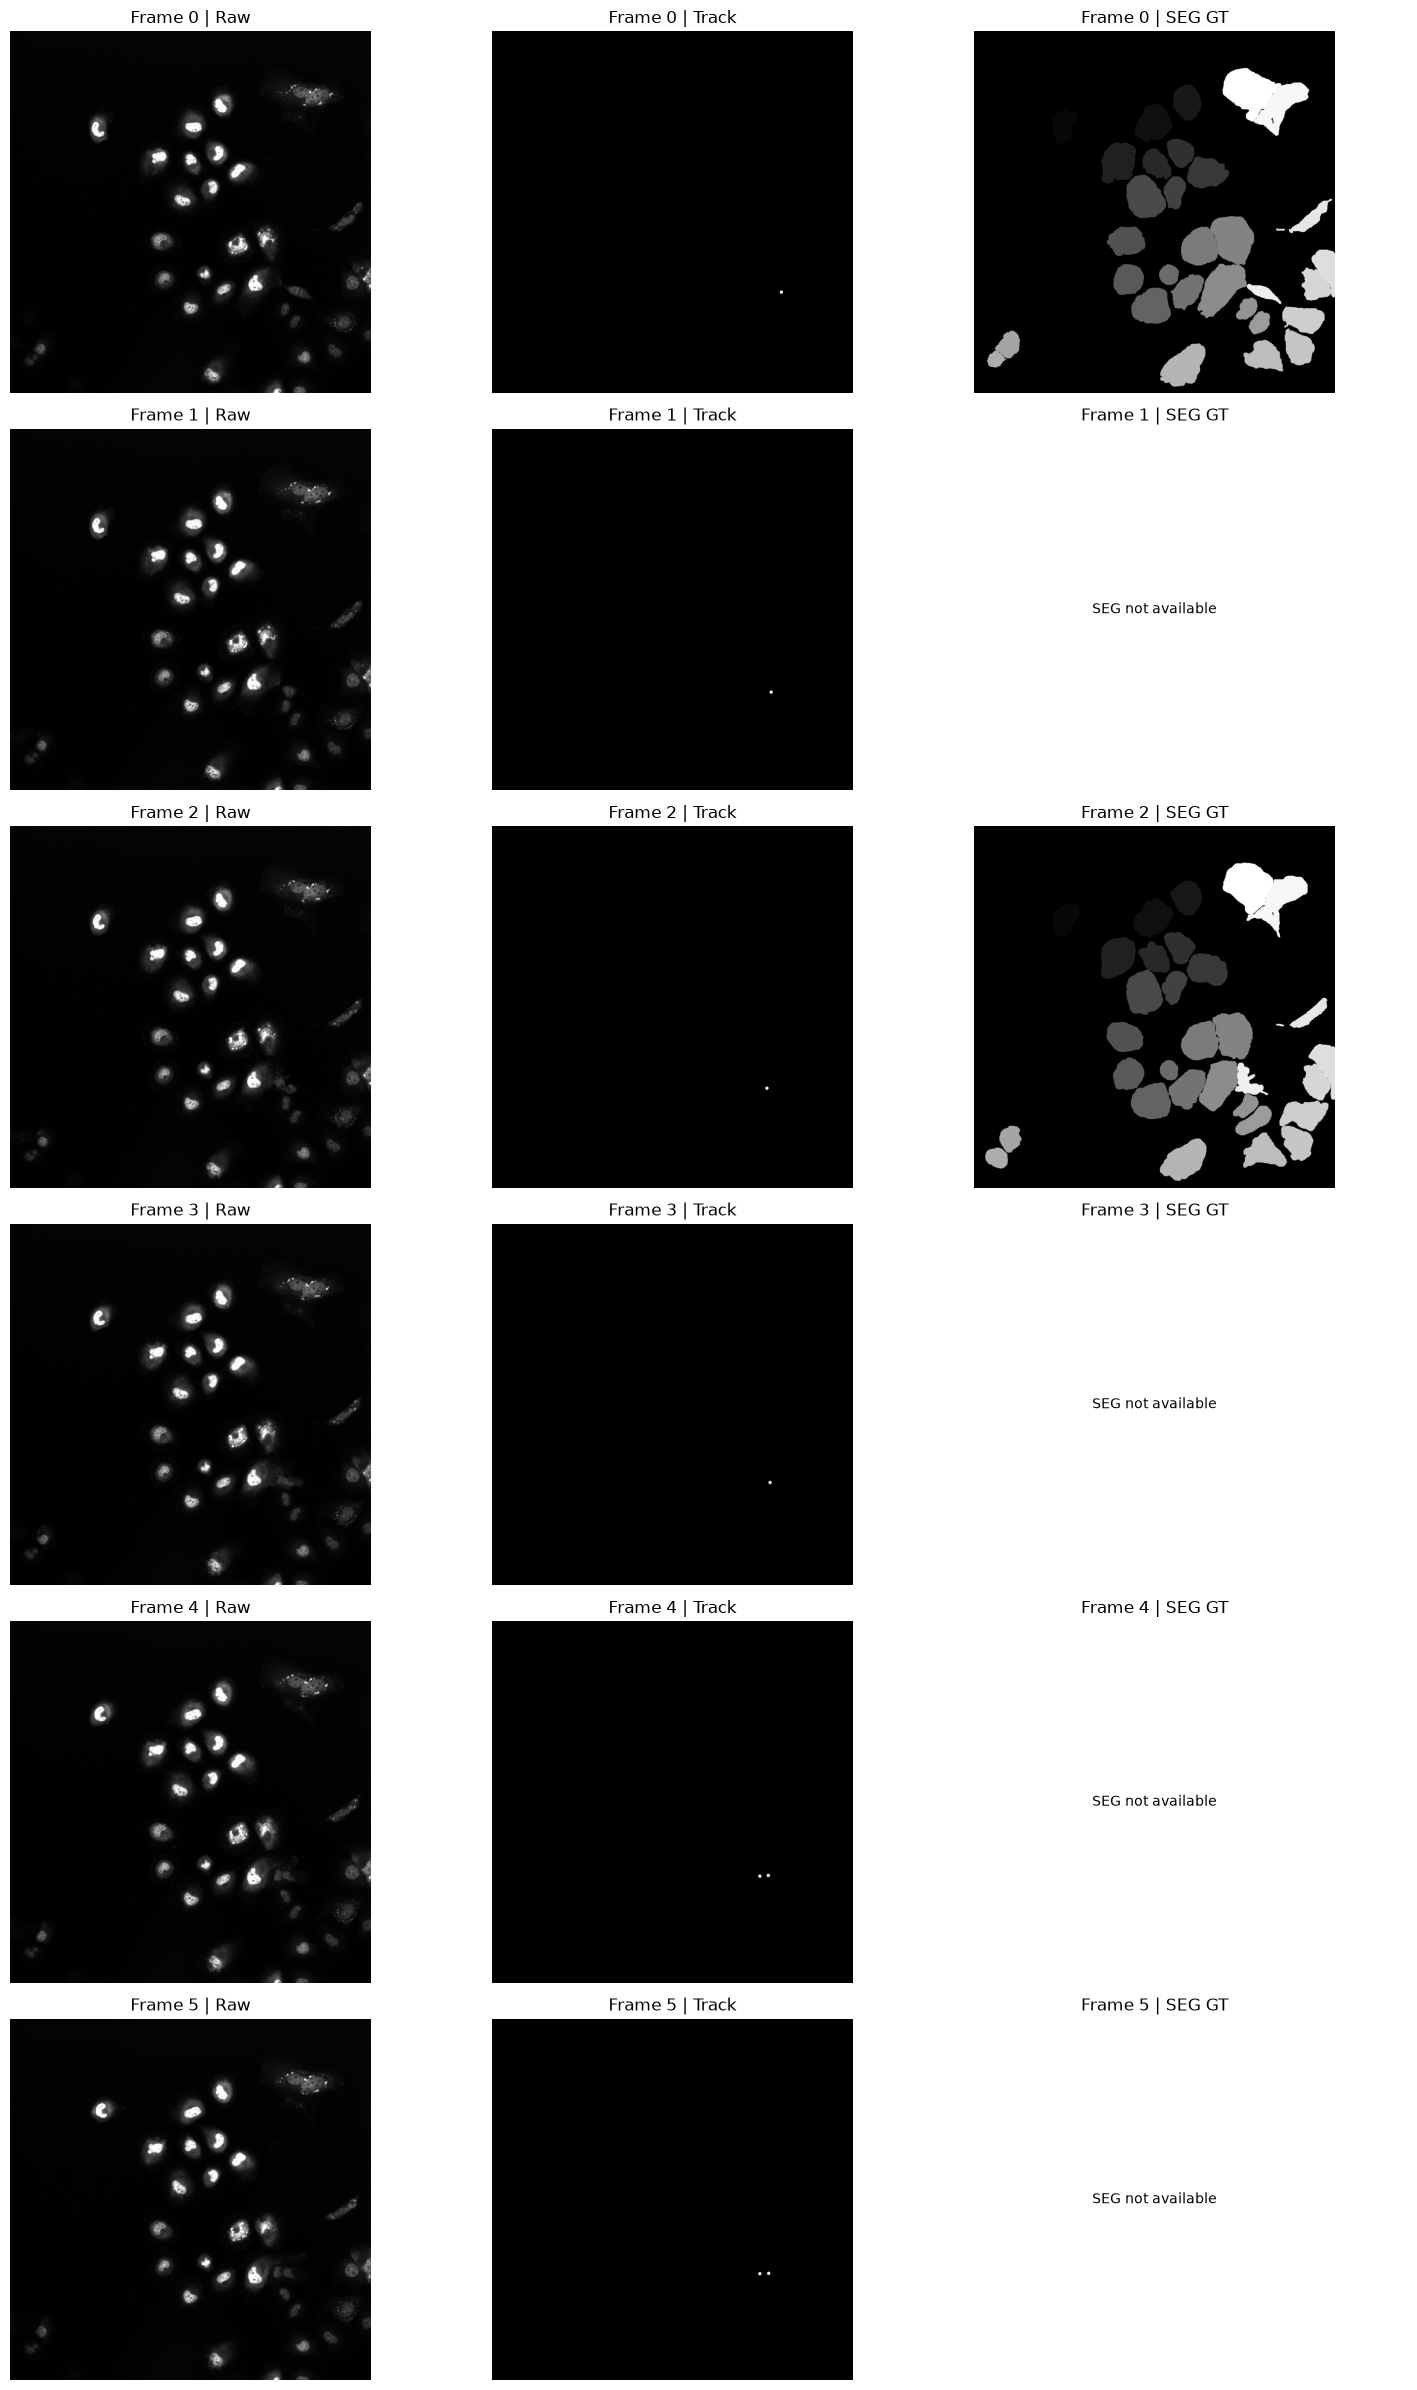

In [92]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

tracks_sorted = (
    tracks
    .loc[tracks["start_frame"] == 0]
    .sort_values(by="end_frame", ascending=True)
)

cell_id = 0
cell_id, start_frame, end_frame, parent_id = tracks_sorted.iloc[cell_id, :].values

cell_id = int(cell_id)
start_frame = int(start_frame)
end_frame = int(end_frame)

children = tracks[
    tracks["parent_id"] == cell_id
]["cell_id"].astype(int).tolist()

print("Cell:", cell_id)
print("Life:", start_frame, "→", end_frame)
print("Children:", children)

start_img = max(end_frame - 5, 0)
end_image = end_frame + 2

frames = range(start_img, end_image + 1)

seg_dir = os.path.join(
    data_dir,
    ds_type,
    cell_type,
    f"{Movie.one}_GT",
    "SEG"
)

fig, axes = plt.subplots(
    nrows=len(frames),
    ncols=3,
    figsize=(15, 4 * len(frames))
)

for row, frame in enumerate(frames):
    raw_path = os.path.join(raw_dir, f"t{frame:03d}.tif")
    raw = np.array(Image.open(raw_path))

    track_path_frame = os.path.join(
        tra_dir,
        f"man_track{frame:03d}.tif"
    )
    track = np.array(Image.open(track_path_frame))

    cell_mask = track == cell_id

    for child in children:
        cell_mask |= track == child

    axes[row, 0].imshow(raw, cmap="gray")
    axes[row, 0].set_title(f"Frame {frame} | Raw")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cell_mask, cmap="gray")
    axes[row, 1].set_title(f"Frame {frame} | Track")
    axes[row, 1].axis("off")

    seg_path = os.path.join(
        seg_dir,
        f"man_seg{frame:03d}.tif"
    )

    if os.path.exists(seg_path):
        seg = np.array(Image.open(seg_path))
        axes[row, 2].imshow(seg, cmap="gray")
        axes[row, 2].set_title(f"Frame {frame} | SEG GT")
    else:
        axes[row, 2].text(
            0.5,
            0.5,
            "SEG not available",
            ha="center",
            va="center"
        )
        axes[row, 2].set_title(f"Frame {frame} | SEG GT")

    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()